Questo notebookl andalizza il dataset costruito nel Notebook01 per capire se è adatto alla costruzione di un sistema di raccomandazione.
In particolare analizzare la sparsità dei dati.

## 1-setup

In [2]:
#Se mancano pacchetti, esegui questa cella una sola volta.
%pip install -q "datasets==3.6.0" pandas pyarrow requests tqdm
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1 -> 26.1.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1 -> 26.1.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
from pathlib import Path
import json
import math
import warnings #gestire warnings
import numpy as np 
import pandas as pd
import pyarrow.parquet as pq 
import matplotlib.pyplot as plt 

warnings.filterwarnings("ignore", category=FutureWarning) #nasconde avvisi per output meno rumoroso
#impostazioni di pandas
pd.set_option("display.max_columns", 80)
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.float_format", lambda x: f"{x:,.6f}")  

## 2 percorsi file

In [4]:
#percorsi
CATEGORY="Electronics"

PROJECT_ROOT = Path("..").resolve() if (Path("..") / "data").exists() else Path(".").resolve()  #determina automaticamente la cartella principale del progetto
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed" / "electronics_intersection" #percorso dati notebook01
ANALYSIS_DIR = PROCESSED_DIR / "analysis" #dove salvare risultati notebook02
ANALYSIS_DIR.mkdir(parents=True, exist_ok=True) #la crea se non esiste già

#percorsi dei file prodotti nel notebook01
ITEMS_PATH = PROCESSED_DIR / "items.parquet"
QA_PATH = PROCESSED_DIR / "qa.parquet"
RATINGS_PATH = PROCESSED_DIR / "ratings.parquet"
SUMMARY_PATH = PROCESSED_DIR / "summary.json"

#dizionario per associare nome leggibile ad ogni percorso
paths={
    "items": ITEMS_PATH,
    "qa": QA_PATH,
    "ratings":RATINGS_PATH,
    "summary": SUMMARY_PATH,
}
#controllo dei percorsi
print("Project root:", PROJECT_ROOT)
print("Processed dir:", PROCESSED_DIR)
print("Analysis dir:", ANALYSIS_DIR)
for name, path in paths.items():
    print(f"{name:8s}->{path} | exists={path.exists()}")

Project root: C:\Users\arsid\Desktop\Tesi-ecommerce
Processed dir: C:\Users\arsid\Desktop\Tesi-ecommerce\data\processed\electronics_intersection
Analysis dir: C:\Users\arsid\Desktop\Tesi-ecommerce\data\processed\electronics_intersection\analysis
items   ->C:\Users\arsid\Desktop\Tesi-ecommerce\data\processed\electronics_intersection\items.parquet | exists=True
qa      ->C:\Users\arsid\Desktop\Tesi-ecommerce\data\processed\electronics_intersection\qa.parquet | exists=True
ratings ->C:\Users\arsid\Desktop\Tesi-ecommerce\data\processed\electronics_intersection\ratings.parquet | exists=True
summary ->C:\Users\arsid\Desktop\Tesi-ecommerce\data\processed\electronics_intersection\summary.json | exists=True


In [5]:
#dati attesi mancanti, in caso avvisa di eseguire prima notebook01
missing =[str(path) for path in paths.values() if not path.exists()]
if missing:
    raise FileNotFoundError(
        "mancano cerci file del notebook01: \n"
        + "\n".join(missing)+ "\n\nEsegui prima il notebook: 01_prepare_electronics_intersection.ipynb"
    )

## 3 lettura dati parquet

In [6]:
#lettura dei metadata dei parquet
def parquet_info(path: Path)->dict:
    pf=pq.ParquetFile(path)
    return{
        "file":path.name,
        "rows":pf.metadata.num_rows,
        "row_groups":pf.metadata.num_row_groups,
        "columns": len(pf.schema_arrow.names),
        "column_names": ", ".join(pf.schema_arrow.names),
    }

parquet_infos=pd.DataFrame([
    parquet_info(ITEMS_PATH),
    parquet_info(QA_PATH),
    parquet_info(RATINGS_PATH),
])

parquet_infos

,file,rows,row_groups,columns,column_names
0,items.parquet,22974,1,12,"parent_asin, title, category, avg_rating, num_ratings, price, store, features_json, description_json, categories_jso..."
1,qa.parquet,180976,1,8,"qa_id, parent_asin, question, answer, questionType, answerType, answerTime, unixTime"
2,ratings.parquet,3484401,18,6,"user_id, parent_asin, asin, rating, timestamp, verified_purchase"


In [7]:
#controlliamo summary.json
if SUMMARY_PATH.exists():
    summary=json.loads(SUMMARY_PATH.read_text(encoding="utf-8"))
    display(pd.DataFrame([summary]).T.rename(columns={0: "rows_from_summary_json"}))
else:
    summary={}
    print("summary.json non trovato. Ricarica notebook 02")

,rows_from_summary_json
items,22974
qa,180976
ratings,3484401


## 4 caricamento dei dati

In [8]:
#caricamento dei dati
def parquet_columns(path: Path)-> list[str]: #funzione che restituisce i nomi delle colonne
    return pq.ParquetFile(path).schema_arrow.names

def columns_keep(path: Path, wanted: list[str])-> list[str]: #funzione che tiene solo le colonne richieste
    available=set(parquet_columns(path))
    return [col for col in wanted if col in available]

items_df=pd.read_parquet(ITEMS_PATH)
qa_df=pd.read_parquet(QA_PATH)

wanted_rating_columns=[
    "user_id","parent_asin","asin","rating","timestamp","verified_purchase",
    "review_title","review_text",#se presenti le colonne testuali, in base a cosa si è scelto nel notebook 01
]

rating_columns=columns_keep(RATINGS_PATH,wanted_rating_columns)
ratings_df=pd.read_parquet(RATINGS_PATH,columns=rating_columns)

print("items_df:", items_df.shape)
print("qa_df:", qa_df.shape)
print("ratings_df:", ratings_df.shape)
print("Colonne rating caricate:", rating_columns)

items_df: (22974, 12)
qa_df: (180976, 8)
ratings_df: (3484401, 6)
Colonne rating caricate: ['user_id', 'parent_asin', 'asin', 'rating', 'timestamp', 'verified_purchase']


In [9]:
display(items_df.head(3))
display(qa_df.head(3))
display(ratings_df.head(3))

,parent_asin,title,category,avg_rating,num_ratings,price,store,features_json,description_json,categories_json,details_json,image_url
0,B00CFGZAT8,"Dock Audio Extender Adapter Converter Cable for iPod iPhone 4 4S iPhone 5 5S iPad, Samsung & Other Smart Phones",Portable Audio & Accessories,3.600000,45,NaN,iteck,[],[],"[""Electronics"", ""Computers & Accessories"", ""Tablet Accessories"", ""Chargers & Adapters""]","""{\""Brand Name\"": \""iTeck\"", \""Item Weight\"": \""0.8 ounces\"", \""Package Dimensions\"": \""6 x 4 x 0.3 inches; 0.8 Ounc...",https://m.media-amazon.com/images/I/41uTuqlHDSL._AC_.jpg
1,B00BGFTSGU,GGS Swivi HD DSLR LCD Universal Foldable Viewfinder Version II with 3.0X Magnification,Camera & Photo,3.700000,52,149.000000,Swivi,[],[],"[""Electronics"", ""Camera & Photo"", ""Accessories"", ""Viewfinders""]","""{\""Product Dimensions\"": \""3.8 x 4.3 x 6.9 inches\"", \""Item Weight\"": \""0.705 ounces\"", \""Item model number\"": \""Sw...",https://m.media-amazon.com/images/I/41BUv5PjMDL._AC_.jpg
2,B00AZOIG9I,BM Premium 2-Pack of NP-85 Batteries and Charger Kit for FujiFilm FinePix S1 SL240 SL260 SL280 SL300 SL305 SL1000 Di...,Camera & Photo,4.700000,345,22.990000,BM Premium,"[""NP85 Li-ion Battery for FujiFilm FinePix SL240 SL260 SL280 SL300 SL305 SL1000 Digital Camera"", ""Battery Specificat...","[""Bring your digital camera back to life with a new battery. Make sure you never miss another once-in-a-lifetime mom...","[""Electronics"", ""Camera & Photo"", ""Accessories"", ""Batteries & Chargers"", ""Batteries"", ""Camera Batteries""]","""{\""Package Dimensions\"": \""6.46 x 3.94 x 1.85 inches\"", \""Item Weight\"": \""6.7 ounces\"", \""Item model number\"": \""N...",https://m.media-amazon.com/images/I/71fbU-87TxL._AC_SL1500_.jpg


,qa_id,parent_asin,question,answer,questionType,answerType,answerTime,unixTime
0,0,0594033926,Is this cover the one that fits the old nook color? Which I believe is 8x5.,Yes this fits both the nook color and the same-shaped nook tablet,yes/no,Y,"Dec 27, 2013","1,388,131,200.000000"
1,1,0594033926,Does it fit Nook GlowLight?,No. The nook color or color tablet,yes/no,N,"Jan 5, 2015","1,420,444,800.000000"
2,2,0594033926,Would it fit Nook 1st Edition? 4.9in x 7.7in ?,"I don't think so. The nook color is 5 x 8 so not sure anything smaller would stay locked in, but would be close.",open-ended,NaN,2 days ago,NaN


,user_id,parent_asin,asin,rating,timestamp,verified_purchase
0,AGCI7FAH4GL5FI65HYLKWTMFZ2CQ,B0047T79VS,B0047T79VS,3.000000,1344406083000,True
1,AFTC6ZR5IKNRDG5JCPVNVMU3XV2Q,B001FWYGJS,B001FWYGJS,4.000000,1427592277000,True
2,AHITBJSS7KYUBVZPX7M2WJCOIVKQ,B00BHC7ZTE,B00BHC7ZTE,5.000000,1432342265000,True


## 5 controlli di coerenza

In [10]:
#controlli generali di coerenza
def pct(numerator, denominator): #funzione che useremo anche dopo per calcolare la percentuale
    if denominator == 0:
        return np.nan
    return numerator/denominator *100

items_set=set(items_df["parent_asin"].dropna()) #insieme parentasin nei metadati, droppando valori nulli
ratings_items_set=set(ratings_df["parent_asin"].dropna()) #insieme parentasin dei rating
qa_items_set=set(qa_df["parent_asin"].dropna()) #insieme parentasin qa
#dizionario con statistiche generali del dataset
basic_stats={
    "num_product_items": items_df["parent_asin"].nunique(), #conta quanti prodotti unici nella tabella items
    "num_rating_rows": len(ratings_df), #conta quante righe di rating presenti
    "num_users":ratings_df["user_id"].nunique(dropna=True), #quanti utenti unici compaiono nei rating
    "num_products_with_ratings": ratings_df["parent_asin"].nunique(dropna=True), #quanti prodotti distinti hanno almeno un rating
    "num_qa_rows":len(qa_df), #quante righe di domande/risposte presenti
    "num_products_with_qa": qa_df["parent_asin"].nunique(dropna=True), #quanti prodotti distinti hanno almeno una domanda/risposta
    "items_parent_asin_unique": bool(items_df["parent_asin"].is_unique), #controlla se parent_asin è unico nella tabella items
    "ratings_products_all_in_items": ratings_items_set.issubset(items_set), #verifica se tutti i prodotti nei rating sono presenti anche nei metadati items
    "qa_products_all_in_items": qa_items_set.issubset(items_set), #controlla se tutti prodotti qa sono presenti anche nei metadati items
    "items_with_rating_pct": pct(len(items_set & ratings_items_set), len(items_set)), #calcola percentuale di prodotti items che hanno almeno un rating
    "items_with_qa_pct": pct(len(items_set & qa_items_set), len(items_set)), #calcola percentuale di prodotti items che hanno almeno una riga QA
}

basic_stats_df=pd.DataFrame.from_dict(basic_stats, orient="index", columns=["value"]) #converte dizionario delle stats generali in tabella pandas
display(basic_stats_df)

basic_stats_df.to_csv(ANALYSIS_DIR/"notebook02_basic_stats.csv")

,value
num_product_items,22974
num_rating_rows,3484401
num_users,2434619
num_products_with_ratings,22974
num_qa_rows,180976
num_products_with_qa,22974
items_parent_asin_unique,True
ratings_products_all_in_items,True
qa_products_all_in_items,True
items_with_rating_pct,100.000000


In [11]:
#se alcuni prodotti sono presenti nei ratings ma non in items (se esce 0 perfetto)
missing_rating_products = ratings_items_set - items_set
#se alcuni prodotti sono presenti nel QA ma assenti in items (se esce 0 perfetto)
missing_qa_products = qa_items_set - items_set
print("Prodotti in ratings ma non in items:", len(missing_rating_products))
print("Prodotti in qa ma non in items:", len(missing_qa_products))
if missing_rating_products:
    print("Esempi ratings fuori items:", list(missing_rating_products)[:5])
if missing_qa_products:
    print("Esempi QA fuori items:", list(missing_qa_products)[:5])

Prodotti in ratings ma non in items: 0
Prodotti in qa ma non in items: 0


## 6 controllo qualità dei dati

In [12]:
#ora bisogna controllare la qualità di questi dati
important_columns={ #dizionario con colonne importanti da controllare
    "items": ["parent_asin","title","category"],
    "qa": ["parent_asin","question","answer"],
    "ratings": ["user_id","parent_asin","rating"],
}
null_rows=[]
#scorriamo le tabelle e colonne da controllare
for df_name, cols in important_columns.items():
    df={"items":items_df, "qa":qa_df, "ratings":ratings_df}[df_name]
    for col in cols:
        if col in  df.columns:
            null_rows.append({
                "table":df_name,
                "column":col,
                "null_count":int(df[col].isna().sum()), #conta quanti valori nulli presenti nella colonna
                "null_pct": pct(int(df[col].isna().sum()), len(df)), #conta la percentuale di valori nulli nella colonna
            })

nulls_df=pd.DataFrame(null_rows)
nulls_df


,table,column,null_count,null_pct
0,items,parent_asin,0,0.000000
1,items,title,0,0.000000
2,items,category,0,0.000000
3,qa,parent_asin,0,0.000000
4,qa,question,0,0.000000
5,qa,answer,0,0.000000
6,ratings,user_id,0,0.000000
7,ratings,parent_asin,0,0.000000
8,ratings,rating,0,0.000000


In [13]:
#vediamo se ci sono rating nulli
invalid_rating_mask= ratings_df["rating"].isna() | ~ratings_df["rating"].between(1,5)
invalid_ratings=ratings_df.loc[invalid_rating_mask]
print("Rating nulli o fuori scala:", len(invalid_ratings))
if len(invalid_ratings)>0:
    display(invalid_ratings.head()) 


Rating nulli o fuori scala: 0


In [14]:
#calcoliamo distribuzione dei voti
rating_dist=(
    ratings_df["rating"].value_counts(dropna=False).sort_index().rename_axis("rating").reset_index(name="count")
)
rating_dist["pct"]=rating_dist["count"]/len(ratings_df)*100 #percentuale di ogni voto sul tot
rating_dist

,rating,count,pct
0,1.000000,399404,11.462630
1,2.000000,195919,5.622745
2,3.000000,264586,7.593443
3,4.000000,573679,16.464207
4,5.000000,2050813,58.856974


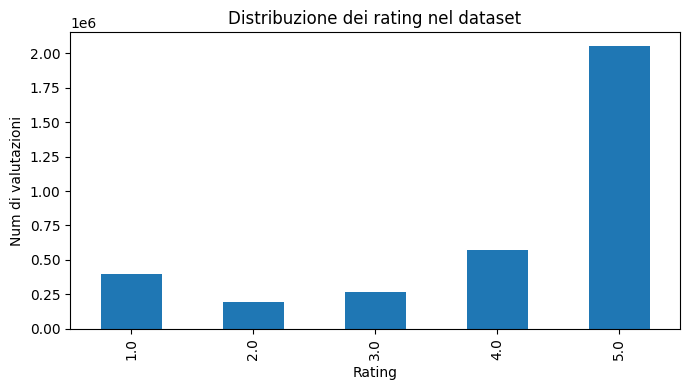

In [15]:
#schema dei dati visti sopra sui rating
plt.figure(figsize=(7,4))
rating_dist.dropna(subset=["rating"]).plot(
    x="rating",y="count",kind="bar",legend=False,ax=plt.gca()
)
plt.title("Distribuzione dei rating nel dataset")
plt.xlabel("Rating")
plt.ylabel("Num di valutazioni")
plt.tight_layout()
plt.show()

In [16]:
#funzione per capire se timestamp sono in sec o millisec
def timestamp_un(series:pd.Series)->str | None:
    values=pd.to_numeric(series.dropna(), errors="coerce").dropna() #converte timestamp in numeri
    if values.empty:
        return None
    median_value=values.median()
    if median_value>1e12: #se compatibile con millisecondi
        return "ms"
    if median_value>1e9: #se compatibile con secondi
        return "s"
    return None
#controlla se esiste colonna timestamp
if "timestamp" in ratings_df.columns:
    timestamp_unit=timestamp_un(ratings_df["timestamp"]) #stima l'unità del timestamp
    print("Unità stimata del timestamp: ",timestamp_unit)

    if timestamp_unit is not None:
        ratings_df["datetime"]=pd.to_datetime(
            ratings_df["timestamp"], unit=timestamp_unit,errors="coerce" #passa a pandas la colonna timestamp da convertire
        )
        print("data minima: ",ratings_df["datetime"].min())
        print("data massima: ",ratings_df["datetime"].max())
        display(ratings_df[["timestamp","datetime"]].head())
    else:
        print("timestamp esiste ma unità non riconosciuta")
else:
    print("Colonna timestamp assente, non puoi usarlo come criterio")

Unità stimata del timestamp:  ms
data minima:  1999-07-23 18:26:11
data massima:  2023-09-11 02:17:59.206000


,timestamp,datetime
0,1344406083000,2012-08-08 06:08:03.000
1,1427592277000,2015-03-29 01:24:37.000
2,1432342265000,2015-05-23 00:51:05.000
3,1419885573000,2014-12-29 20:39:33.000
4,1589664572977,2020-05-16 21:29:32.977


In [17]:
#controlliamo duplicati userid+parentasin
pair_columns=["user_id","parent_asin"]
duplicate_mask=ratings_df.duplicated(pair_columns,keep=False)#crea maschera che marca tutte le righe appartenenti a coppie utente-prodotto duplicate
num_duplicate_rows=int(duplicate_mask.sum()) #conta righe duplicate
num_duplicate_pairs=int(ratings_df.loc[duplicate_mask,pair_columns].drop_duplicates().shape[0]) #conta coppie duplicate
print("Righe coinvolte in duplicati user_id+parent_asin:", num_duplicate_rows)
print("Coppie duplicate distinte:", num_duplicate_pairs)

if num_duplicate_rows>0:
    display( #seleziona solo righe duplicate, e le ordina
        ratings_df.loc[duplicate_mask].sort_values(pair_columns+(["timestamp"] if "timestamp" in ratings_df.columns else [])).head(10)
    )


Righe coinvolte in duplicati user_id+parent_asin: 68896
Coppie duplicate distinte: 31666


,user_id,parent_asin,asin,rating,timestamp,verified_purchase,datetime
3446379,AE22AIUGNSL7UE6R2OSZ3XGMIZMQ,B003Z2NIH2,B003Z2NIH2,2.000000,1360068622000,True,2013-02-05 12:50:22.000
3446380,AE22AIUGNSL7UE6R2OSZ3XGMIZMQ,B003Z2NIH2,B003Z2NIH2,2.000000,1360068622000,True,2013-02-05 12:50:22.000
3446381,AE22AIUGNSL7UE6R2OSZ3XGMIZMQ,B003Z2NIH2,B003Z2NIH2,2.000000,1360068622000,True,2013-02-05 12:50:22.000
3446382,AE22AIUGNSL7UE6R2OSZ3XGMIZMQ,B003Z2NIH2,B003Z2NIH2,2.000000,1360068622000,True,2013-02-05 12:50:22.000
3446383,AE22AIUGNSL7UE6R2OSZ3XGMIZMQ,B003Z2NIH2,B003Z2NIH2,2.000000,1360068622000,True,2013-02-05 12:50:22.000
517149,AE22E3XNIF5TITEAJXHT55LD5QUQ,B0071369M2,B007136E0O,5.000000,1507983964568,True,2017-10-14 12:26:04.568
517150,AE22E3XNIF5TITEAJXHT55LD5QUQ,B0071369M2,B007136E0O,5.000000,1507983964568,True,2017-10-14 12:26:04.568
3440251,AE22IPEIUZH764VWYNIIVDM54YBA,B008KCSPRK,B008KCSPRK,1.000000,1397608765000,True,2014-04-16 00:39:25.000
3440252,AE22IPEIUZH764VWYNIIVDM54YBA,B008KCSPRK,B008KCSPRK,1.000000,1397608765000,True,2014-04-16 00:39:25.000
3355803,AE22LFQUJPE5ZLCCEWTOGCHJXURQ,B0090SVDEK,B0090SVDEK,5.000000,1347641749000,False,2012-09-14 16:55:49.000


,year,count,pct
0,1999,12,0.000344
1,2000,262,0.007519
2,2001,379,0.010877
3,2002,582,0.016703
4,2003,900,0.025829
5,2004,1369,0.039289
6,2005,3892,0.111698
7,2006,11739,0.336902
8,2007,35201,1.010245
9,2008,41699,1.196734


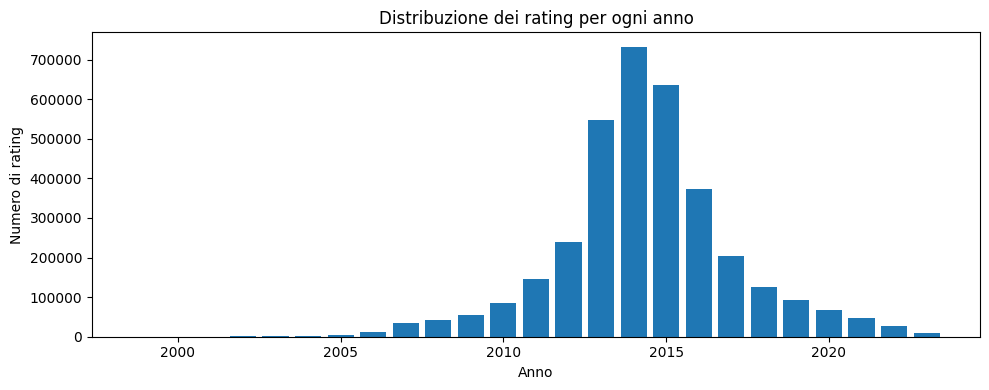

In [18]:
#andiamo ad analizzare le valutazioni per ogni anno
if "datetime" in ratings_df.columns:
    ratings_each_year =(
        ratings_df["datetime"]
        .dt.year
        .value_counts()
        .sort_index()
        .rename_axis("year")
        .reset_index(name="count")
    )

    ratings_each_year["pct"]=ratings_each_year["count"]/len(ratings_df)*100
    display(ratings_each_year)
    plt.figure(figsize=(10,4))
    plt.bar(ratings_each_year["year"], ratings_each_year["count"])
    plt.title("Distribuzione dei rating per ogni anno")
    plt.xlabel("Anno")
    plt.ylabel("Numero di rating")
    plt.tight_layout()
    plt.show()

## 7 costruzione tabella nuova pulita

Costruiamo la tabella sistemata:
rimuoviamo le righe non valide, duplicate.

In [19]:
def build_int_table(ratings: pd.DataFrame) ->pd.DataFrame: #funzione per pulire e togliere duplicati
    base=ratings.copy() #crea copia
    base=base.dropna(subset=["user_id","parent_asin","rating"]) #rimuove righe senza utente, prodotto, rating
    base=base[base["rating"].between(1,5)].copy() #mantiene rating fra 1 e 5

    if "timestamp" in base.columns:
        base=base.sort_values(["user_id","parent_asin","timestamp"]) #ordina valutazioni per utente, prodotto e timestamp
        interactions=base.drop_duplicates(["user_id","parent_asin"],keep="last").copy()#per ogni coppia tiene solo l'ultima
    else:
        interactions=( #come fallback nel caso di assenza di timestamp usa media dei rating per coppia utente-prodotto
            base.groupby(["user_id","parent_asin"], as_index=False).agg(rating=("rating","mean"))
        )
    return interactions.reset_index(drop=True) #restituisce interazioni pulite con indice ricreato da zero

interactions_df=build_int_table(ratings_df) #applica la funzione ai rating

print("Righe rating originali: ",f"{len(ratings_df):,}")
print("Interazioni dopo la pulizia:",f"{len(interactions_df):,}")
print("Righe rimosse nella pulizia:",f"{len(ratings_df)-len(interactions_df):,}")
display(interactions_df.head())

Righe rating originali:  3,484,401
Interazioni dopo la pulizia: 3,447,171
Righe rimosse nella pulizia: 37,230


,user_id,parent_asin,asin,rating,timestamp,verified_purchase,datetime
0,AE2222FRPDMNOMYOMCWIANTXP7UQ,B007ZHAYL6,B007ZHAYL6,5.000000,1419287222000,True,2014-12-22 22:27:02
1,AE22236AFRRSMQIKGG7TPTB75QEA,B000JREMTO,B000JREMTO,5.000000,1275251437000,True,2010-05-30 20:30:37
2,AE22236AFRRSMQIKGG7TPTB75QEA,B003ZDO2LM,B003ZDO2LM,5.000000,1311718723000,True,2011-07-26 22:18:43
3,AE22236AFRRSMQIKGG7TPTB75QEA,B005CG2AX2,B005CG2AX2,4.000000,1344043262000,False,2012-08-04 01:21:02
4,AE222ARFTTB3OUTW2RXSHTO3DBZQ,B001F7AJKI,B001F7AJKI,5.000000,1454448914000,True,2016-02-02 21:35:14


## 8 analisi degli utenti

Analizziamo gli utenti, quante interazioni ha ciascun utente

In [20]:
def analyze_quantilies(counts: pd.Series, name: str)-> pd.DataFrame: #funzione per riassumere conteggi
    quantiles=counts.quantile([0.25,0.50,0.75,0.90,0.95,0.99]).to_dict()
    data={
        "entity":name,
        "num_entities":counts.shape[0],
        "mean":counts.mean(),
        "median:":counts.median(),
        "min":counts.min(),
        "p25":quantiles.get(0.25),
        "p75":quantiles.get(0.75),
        "p90":quantiles.get(0.90),
        "p95":quantiles.get(0.95),
        "p99":quantiles.get(0.99),
        "max":counts.max(),
    }
    return pd.DataFrame([data])

user_counts=interactions_df["user_id"].value_counts()
user_summary=analyze_quantilies(user_counts, "users")
user_summary

,entity,num_entities,mean,median:,min,p25,p75,p90,p95,p99,max
0,users,2434619,1.415898,1.000000,1,1.000000,1.000000,2.000000,3.000000,6.000000,98


In [21]:
user_thresholds=[1,2,3,5,10,20,50] #soglie da testare minime di interazione per ogni utente
rows=[]

for t in user_thresholds:
    valid_users=user_counts[user_counts>=t].index #.index prende solo identificativi degli utenti rimasti
    filtered=interactions_df[interactions_df["user_id"].isin(valid_users)] #filtriamo tabella, tenendo solo utenti validi che rispettano la soglia di interazioni

    rows.append({
        "min_interactions":t,
        "num_users":filtered["user_id"].nunique(), #num utenti unici rimasti
        "num_products":filtered["parent_asin"].nunique(), #num prodotti unici rimasti
        "num_interactions":len(filtered), #num interazioni rimaste
        "percentage_users":filtered["user_id"].nunique()/interactions_df["user_id"].nunique()*100,
        "percentage_interactions":len(filtered)/len(interactions_df)*100
    })

user_threshold_table=pd.DataFrame(rows)
user_threshold_table

,min_interactions,num_users,num_products,num_interactions,percentage_users,percentage_interactions
0,1,2434619,22974,3447171,100.000000,100.000000
1,2,535461,22669,1548013,21.993626,44.906766
2,3,206190,22115,889471,8.469087,25.802927
3,5,55824,20586,393849,2.292926,11.425282
4,10,7399,15584,100497,0.303908,2.915347
5,20,692,7650,17788,0.028423,0.516017
6,50,13,764,846,0.000534,0.024542


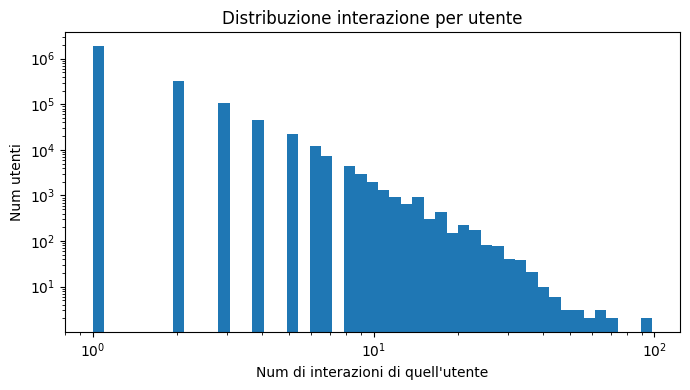

In [22]:
plt.figure(figsize=(7,4))
counts=user_counts[user_counts>0]
#crea 50 intervalli su scala logaritmica tra 10^0=1 e max num di interazioni=10^2=100 circa (in realtà 98)
#essendo molto sbilanciata, tanti utenti hanno poche interazioni, pochi utenti ne hanno molte.super
spaces=np.logspace(0,np.log10(counts.max()),50) if counts.max()>1 else 1 
plt.hist(counts,bins=spaces)
plt.xscale("log")
plt.yscale("log")
plt.title("Distribuzione interazione per utente")
plt.xlabel("Num di interazioni di quell'utente")
plt.ylabel("Num utenti")
plt.tight_layout()
plt.show()

## 9 analisi dei prodotti
vogliamo evitare prodotti con pochissimi rating, ma anche evitare filtri troppo aggressivi

In [23]:
item_counts=interactions_df["parent_asin"].value_counts() #contiamo quante interazioni ha ogni prodotto
item_summary=analyze_quantilies(item_counts, "products") #riepilogo della distribuzione
item_summary

,entity,num_entities,mean,median:,min,p25,p75,p90,p95,p99,max
0,products,22974,150.046618,52.000000,1,20.000000,137.000000,317.000000,536.000000,"1,540.700000",19205


In [24]:
#soglie di thresholds da testare
item_thresholds=[1,2,5,10,20,50,100]
rows=[]
for t in item_thresholds:
    valid_items=item_counts[item_counts>=t].index
    filtered=interactions_df[interactions_df["parent_asin"].isin(valid_items)]
    rows.append({ #aggiungiamo dizionario con le statistiche sulla soglia corrente
        "min_product_interactions":t,
        "num_users":filtered["user_id"].nunique(),
        "num_products_remaining":filtered["parent_asin"].nunique(),
        "num_interactions":len(filtered),
        "percentage_users":filtered["user_id"].nunique()/interactions_df["user_id"].nunique()*100,
        "percentage_products":filtered["parent_asin"].nunique()/interactions_df["parent_asin"].nunique()*100,
        "percentage_Interactions":len(filtered)/len(interactions_df)*100
    })

item_thresholds_table=pd.DataFrame(rows)
item_thresholds_table

,min_product_interactions,num_users,num_products_remaining,num_interactions,percentage_users,percentage_products,percentage_Interactions
0,1,2434619,22974,3447171,100.000000,100.000000,100.000000
1,2,2434487,22734,3446931,99.994578,98.955341,99.993038
2,5,2433132,21853,3444256,99.938923,95.120571,99.915438
3,10,2427288,20211,3432824,99.698885,87.973361,99.583804
4,20,2405793,17261,3390535,98.815995,75.132759,98.357030
5,50,2313643,11768,3211164,95.031009,51.223122,93.153603
6,100,2147285,7523,2907380,88.197989,32.745713,84.341044


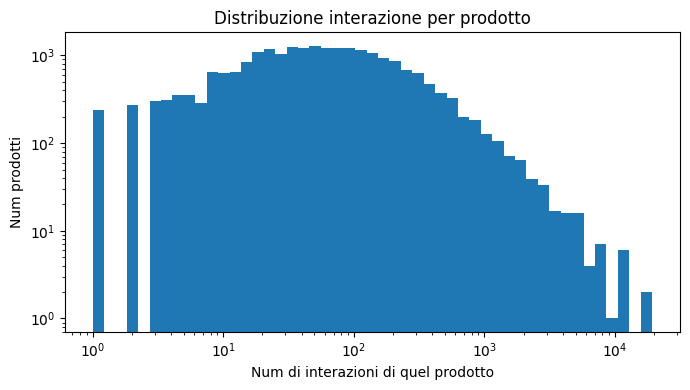

In [25]:
plt.figure(figsize=(7,4))
counts=item_counts[item_counts>0]
spaces=np.logspace(0,np.log10(counts.max()),50) if counts.max()>1 else 1 
plt.hist(counts,bins=spaces)
plt.xscale("log")
plt.yscale("log")
plt.title("Distribuzione interazione per prodotto")
plt.xlabel("Num di interazioni di quel prodotto")
plt.ylabel("Num prodotti")
plt.tight_layout()
plt.show()

## 10 analisi QA per prodotto
inizialmente potrebbe non essere aggiunto, ma è utile vedere ora quante domande/risposte sono associate ai prodotti

In [26]:
qa_counts=qa_df["parent_asin"].value_counts() #conta quante righe associate a ciascun prodotto
total_products=items_df["parent_asin"].nunique() #calcola n tot di prodotti nel catalogo

products_with_qa=qa_counts.shape[0] #num prodotti con almeno una riga qa
total_qa_rows=len(qa_df)

qa_overview=pd.DataFrame([{
    "tot_products":total_products,#num tot di prodotti
    "products_with_qa":products_with_qa,
    "percentage_with_qa":products_with_qa/total_products*100,
    "total_qa_rows":total_qa_rows,
    "mean-qa_perproducts":qa_counts.mean(),
    "median-qa_perproducts":qa_counts.median(),
    "max-qa_perproduct":qa_counts.max()
}])
qa_summary=analyze_quantilies(qa_counts, "products_with_qa")
display(qa_overview)
display(qa_summary)

,tot_products,products_with_qa,percentage_with_qa,total_qa_rows,mean-qa_perproducts,median-qa_perproducts,max-qa_perproduct
0,22974,22974,100.000000,180976,7.877427,9.000000,40


,entity,num_entities,mean,median:,min,p25,p75,p90,p95,p99,max
0,products_with_qa,22974,7.877427,9.000000,1,6.000000,10.000000,10.000000,10.000000,10.000000,40


In [ ]:
#definiamo soglie minime delle righe di QA
qa_thresholds=[1,2,3,4,10,20,50]
rows=[]

for t in qa_thresholds:
    valid_qa_items=qa_counts[qa_counts>=t].index
    qa_filtered=qa_df[qa_df["parent_asin"].isin(valid_qa_items)]#filtriamo tabella tenendo solo righe dei prodotti validi per questa thresholds
    interactions_filtered=interactions_df[
        interactions_df["parent_asin"].isin(valid_qa_items)#filtriamo le interazioni rating degli stessi prodotti per capire se sono validi

    ]
    rows.append({
        "minqa_rows":t,
        "num_products":len(valid_qa_items), #quanti prodotti rimangono
        "numqa_rows":len(qa_filtered), #quante righe qa rimangono
        "numusers_withratings":interactions_filtered["user_id"].nunique(), #quanti utenti hanno rating su quei prodotti
        "num_interactions":len(interactions_filtered),#quante interazioni rating rimangono
        "percentage_products":len(valid_qa_items)/items_df["parent_asin"].nunique() *100,  # %prodotti mantenuti
        "percentage_qarows":len(qa_filtered)/len(qa_df)*100, # %righe qa mantenute
        "percentage_interactions":len(interactions_filtered)/len(interactions_df)*100 # % interazioni rating mantenuti
    })

qa_thresholds_table=pd.DataFrame(rows)
qa_thresholds_table

,minqa_rows,num_products,numqa_rows,numusers_withratings,num_interactions,percentage_products,percentage_qarows,percentage_interactions
0,1,22974,180976,2434619,3447171,100.000000,100.000000,100.000000
1,2,22963,180965,2432176,3442948,99.952120,99.993922,99.877494
2,3,22931,180901,2431575,3441875,99.812832,99.958558,99.846367
3,4,21037,175219,2395388,3374639,91.568730,96.818915,97.895898
4,10,11448,114891,2027052,2727338,49.830243,63.484108,79.118152
5,20,28,625,11901,11936,0.121877,0.345350,0.346255
6,50,0,0,0,0,0.000000,0.000000,0.000000
